# RANDOM FOREST


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import roc_curve, roc_auc_score

In [2]:
ruta = r"C:\Users\jhonn\Desktop\NEOLAND\PROYECTO - COCHE\dataset\coches_limpio.csv"
df = pd.read_csv(ruta)

In [4]:
# Duplicados: mismo coche publicado en varias provincias
# (todas las columnas iguales salvo la provincia)
cols_sin_provincia = [c for c in df.columns if c != "provincia"]

dup = df.duplicated(subset=cols_sin_provincia, keep="first")
print(f"Duplicados entre provincias: {dup.sum()} ({dup.mean():.1%})")

# Ejemplo para comprobar que son el mismo coche
df[df.duplicated(subset=cols_sin_provincia, keep=False)].sort_values(cols_sin_provincia).head(6)

Duplicados entre provincias: 15576 (17.9%)


,price_eur,make,model_group,fuel,tipo_hibrido,transmission,body_grupo,provincia,antiguedad,mileage_km,km_anio,power_hp
13304,5790,Citroen,C3,Gasolina,No híbrido,Manual,Turismo,Valladolid,8.435318,154006,18257.283836,82.0
13317,5790,Citroen,C3,Gasolina,No híbrido,Manual,Turismo,Salamanca,8.435318,154006,18257.283836,82.0
22907,5985,Fiat,Punto,Gasolina,No híbrido,Manual,Turismo,Santa Cruz de Tenerife,10.773443,141616,13144.915883,77.0
22939,5985,Fiat,Punto,Gasolina,No híbrido,Manual,Turismo,Las Palmas,10.773443,141616,13144.915883,77.0
29476,5990,Citroen,C1,Gasolina,No híbrido,Manual,Turismo,Las Palmas,9.357974,107854,11525.357958,82.0
29477,5990,Citroen,C1,Gasolina,No híbrido,Manual,Turismo,Santa Cruz de Tenerife,9.357974,107854,11525.357958,82.0


In [5]:
# Eliminar y quedarse con la primera aparición
df = df.drop_duplicates(subset=cols_sin_provincia, keep="first").reset_index(drop=True)
df.shape

(71220, 12)

In [6]:
display(df)

,price_eur,make,model_group,fuel,tipo_hibrido,transmission,body_grupo,provincia,antiguedad,mileage_km,km_anio,power_hp
0,62990,Mercedes-Benz,GLC,Gasolina,No híbrido,Automático,NaN,Córdoba,4.334018,90514,20884.547378,390.0
1,27990,Ebro,s800,Gasolina,No híbrido,Automático,NaN,Málaga,1.418207,18359,12945.221525,147.0
2,27490,Mercedes-Benz,C-Klasse,Diésel,No híbrido,Automático,Turismo,Barcelona,6.748802,73500,10890.821501,160.0
3,23200,Mazda,Mazda3,Híbrido gasolina,MHEV,Automático,Turismo,Barcelona,1.585216,30775,19413.762953,141.0
4,11545,Dacia,Spring,Eléctrico,No híbrido,Automático,NaN,Barcelona,3.748118,33466,8928.748356,45.0
...,...,...,...,...,...,...,...,...,...,...,...,...
71215,14545,Renault,Clio,Gasolina,No híbrido,Manual,Turismo,Valencia,2.535250,32021,12630.313445,91.0
71216,14790,SEAT,Leon,Gasolina,No híbrido,Manual,Turismo,Zaragoza,8.035592,88511,11014.869761,129.0
71217,23790,Tesla,Model 3,Eléctrico,No híbrido,Automático,Turismo,Zaragoza,6.368241,87153,13685.568895,441.0
71218,13272,Jeep,Compass,Gasolina,No híbrido,Manual,SUV,Madrid,5.368925,133411,24848.734192,129.0


In [8]:
X = df[["make", "model_group", "fuel", "tipo_hibrido", "transmission",
        "body_grupo", "provincia", "antiguedad", "mileage_km", "km_anio", "power_hp"]]
y = df["price_eur"]

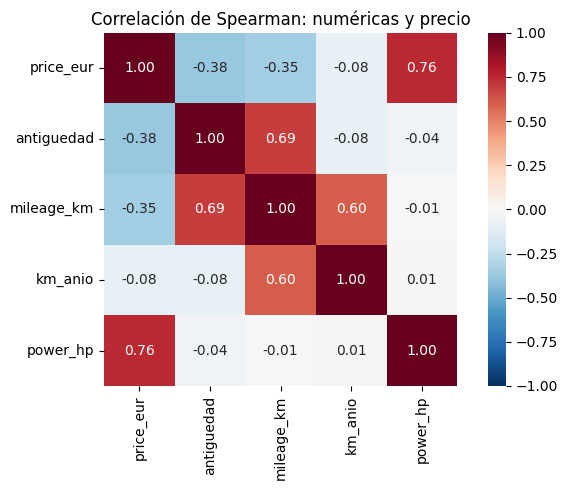

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

cols = ["price_eur", "antiguedad", "mileage_km", "km_anio", "power_hp"]
corr = df[cols].corr(method="spearman")

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Correlación de Spearman: numéricas y precio")
plt.tight_layout()
plt.show()

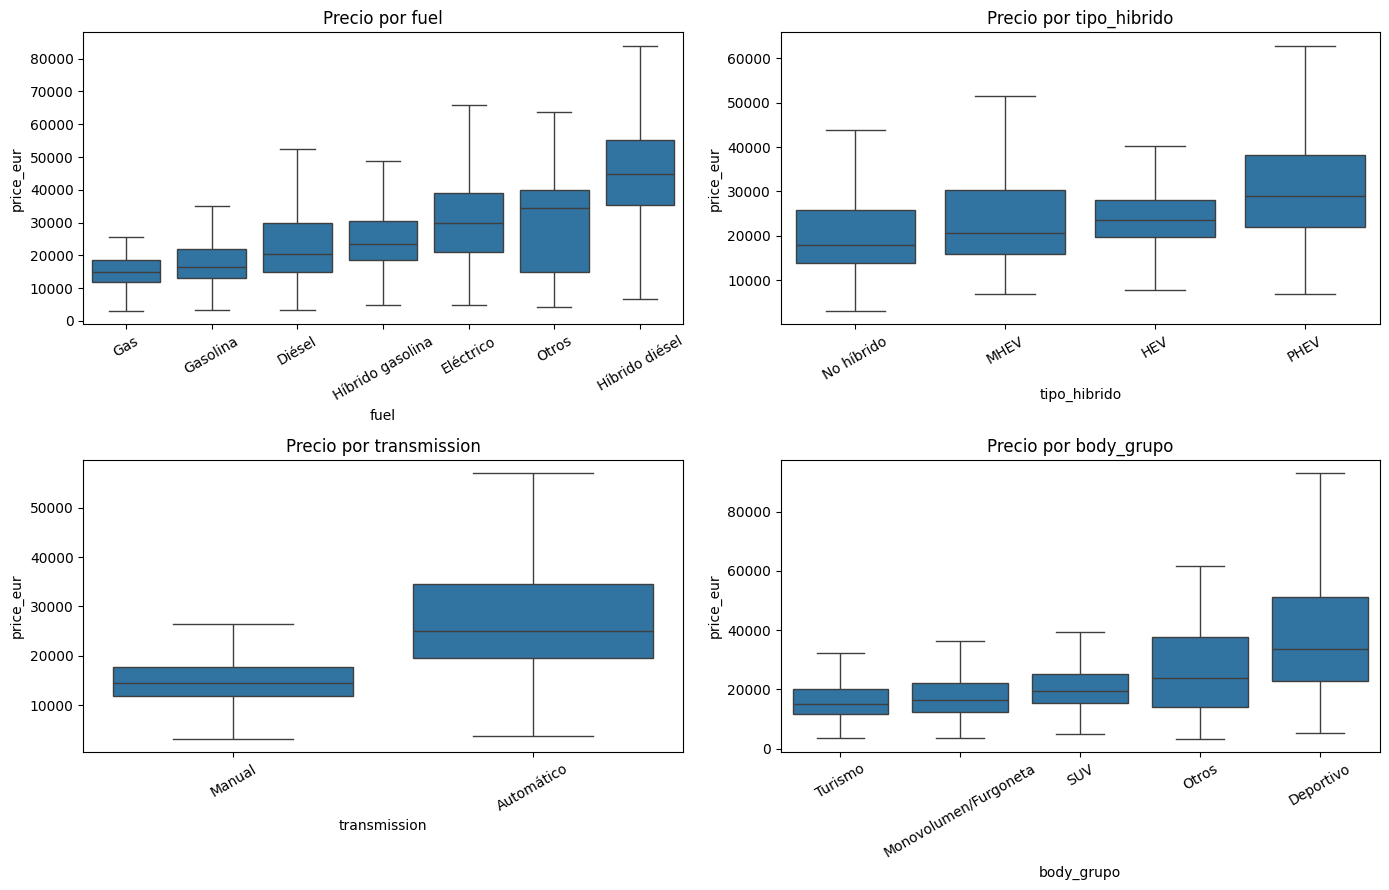

In [15]:
cols_pocas = ["fuel", "tipo_hibrido", "transmission", "body_grupo"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, col in zip(axes.flatten(), cols_pocas):
    # ordenar las categorías de más barata a más cara
    orden = df.groupby(col)["price_eur"].median().sort_values().index
    sns.boxplot(data=df, x=col, y="price_eur", order=orden, showfliers=False, ax=ax)
    ax.set_title(f"Precio por {col}")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

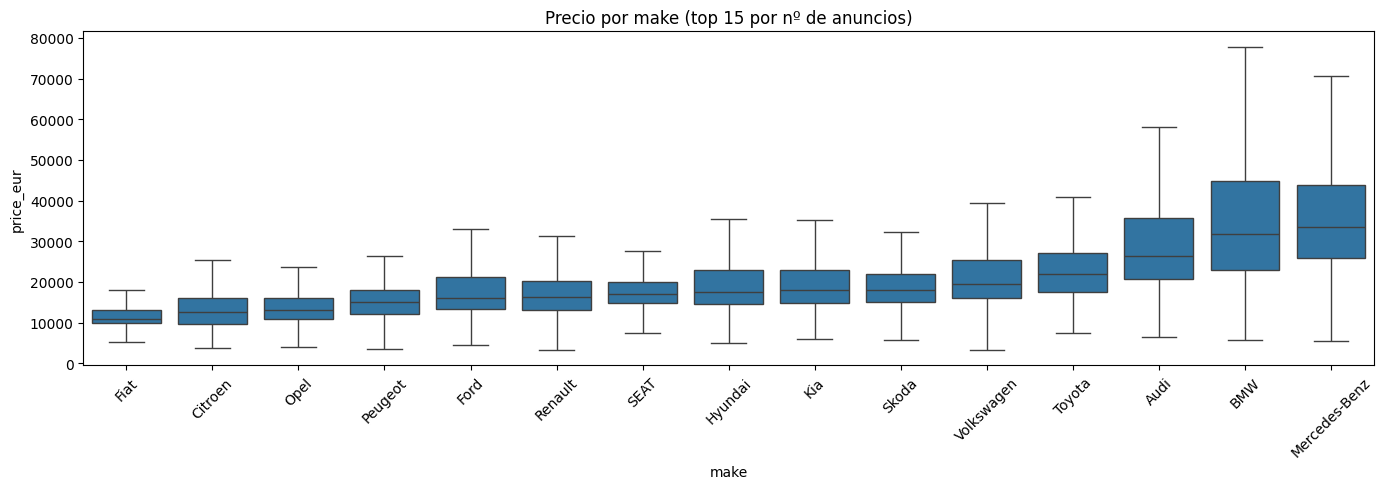

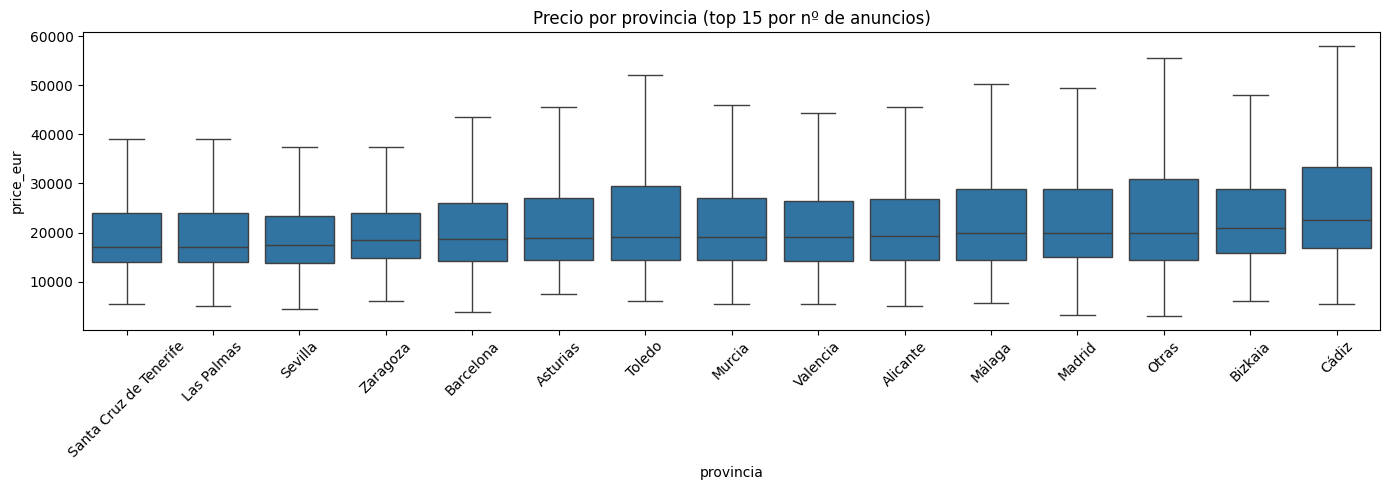

In [16]:
for col in ["make", "provincia"]:
    top15 = df[col].value_counts().head(15).index
    datos = df[df[col].isin(top15)]
    orden = datos.groupby(col)["price_eur"].median().sort_values().index

    plt.figure(figsize=(14, 5))
    sns.boxplot(data=datos, x=col, y="price_eur", order=orden, showfliers=False)
    plt.title(f"Precio por {col} (top 15 por nº de anuncios)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [19]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder

# 1. Carga
df = pd.read_csv(r"C:\Users\jhonn\Desktop\NEOLAND\PROYECTO - COCHE\dataset\coches_limpio.csv")

# 2. Quitar duplicados entre provincias (mismo coche en varias sedes)
cols_sin_provincia = [c for c in df.columns if c != "provincia"]
df = df.drop_duplicates(subset=cols_sin_provincia, keep="first").reset_index(drop=True)

# 3. Cambio a booleano (1 = automático, 0 = manual)
df["es_automatico"] = (df["transmission"] == "Automático").astype(int)

# 4. X e y
X = df[["make", "model_group", "fuel", "tipo_hibrido", "es_automatico",
        "body_grupo", "provincia", "antiguedad", "mileage_km", "km_anio", "power_hp"]]
y = np.log(df["price_eur"])

# 5. Split: test (20 %) y, dentro de train, validación (15 %)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.15, random_state=42)
X_tr, X_val, X_test = X_tr.copy(), X_val.copy(), X_test.copy()

# 6. Imputación (aprendida en X_tr)
med_modelo = X_tr.groupby("model_group")["power_hp"].median()
med_marca  = X_tr.groupby("make")["power_hp"].median()
med_global = X_tr["power_hp"].median()
moda_body  = X_tr.groupby("model_group")["body_grupo"].agg(
    lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)

for d in [X_tr, X_val, X_test]:
    d["power_hp"] = (d["power_hp"].fillna(d["model_group"].map(med_modelo))
                     .fillna(d["make"].map(med_marca)).fillna(med_global))
    d["body_grupo"] = (d["body_grupo"].fillna(d["model_group"].map(moda_body))
                       .fillna("Desconocido"))

# 7. Encoding texto → número (aprendido en X_tr)
cat_cols = ["make", "model_group", "fuel", "tipo_hibrido", "body_grupo", "provincia"]
enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
enc.fit(X_tr[cat_cols])
for d in [X_tr, X_val, X_test]:
    d[cat_cols] = enc.transform(d[cat_cols])

# 8. Comprobaciones
print("df:", df.shape)
print("Shapes:", X_tr.shape, X_val.shape, X_test.shape)
print("Nulos:", X_tr.isna().sum().sum(), X_val.isna().sum().sum(), X_test.isna().sum().sum())
print("Columnas de texto restantes:", list(X_tr.select_dtypes(exclude="number").columns))

df: (71220, 13)
Shapes: (48429, 11) (8547, 11) (14244, 11)
Nulos: 0 0 0
Columnas de texto restantes: []


In [22]:
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score

def metricas(y_real_log, y_pred_log):
    # Pasar de log a euros
    real = np.exp(y_real_log)
    pred = np.exp(y_pred_log)
    return {
        "MAE_€": round(mean_absolute_error(real, pred)),
        "MAPE_%": round(mean_absolute_percentage_error(real, pred) * 100, 2),
        "R2": round(r2_score(real, pred), 3),
    }


In [23]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=100,      # nº de árboles
    min_samples_leaf=5,    # mínimo de coches por hoja (evita memorizar)
    n_jobs=-1,             # usa todos los núcleos del ordenador
    random_state=42
)
rf.fit(X_tr, y_tr)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,5
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [24]:
resultados = pd.DataFrame({
    "train": metricas(y_tr, rf.predict(X_tr)),
    "val":   metricas(y_val, rf.predict(X_val)),
})
resultados

,train,val
MAE_€,1780.000,2562.000
MAPE_%,6.910,9.690
R2,0.943,0.891


In [25]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score

umbral = y_tr.median()               # mediana del log(precio) en train
print("Umbral:", round(np.exp(umbral)), "€")

pred_val = rf.predict(X_val)          # precio estimado (en log)

y_real_clase = (y_val > umbral).astype(int)     # 1 = caro de verdad
y_pred_clase = (pred_val > umbral).astype(int)  # 1 = el modelo dice caro

Umbral: 19290 €


              precision    recall  f1-score   support

      Barato       0.92      0.92      0.92      4187
        Caro       0.93      0.93      0.93      4360

    accuracy                           0.93      8547
   macro avg       0.93      0.93      0.93      8547
weighted avg       0.93      0.93      0.93      8547



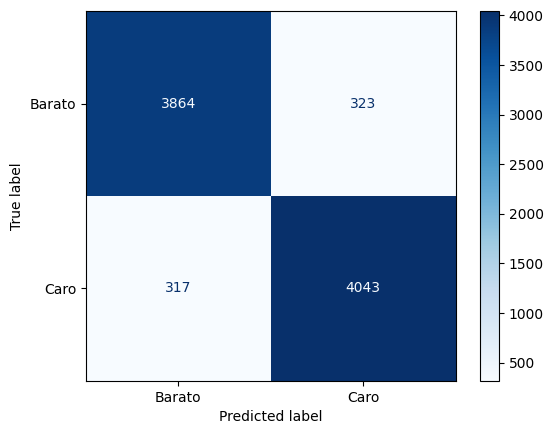

In [26]:
print(classification_report(y_real_clase, y_pred_clase, target_names=["Barato", "Caro"]))

ConfusionMatrixDisplay(confusion_matrix(y_real_clase, y_pred_clase),
                       display_labels=["Barato", "Caro"]).plot(cmap="Blues")
plt.show()

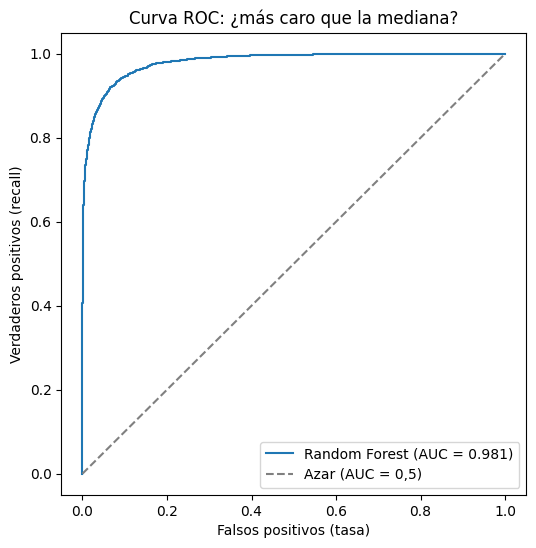

In [27]:
fpr, tpr, _ = roc_curve(y_real_clase, pred_val)   # el precio estimado hace de "puntuación"
auc = roc_auc_score(y_real_clase, pred_val)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "--", color="grey", label="Azar (AUC = 0,5)")
plt.xlabel("Falsos positivos (tasa)")
plt.ylabel("Verdaderos positivos (recall)")
plt.title("Curva ROC: ¿más caro que la mediana?")
plt.legend()
plt.show()

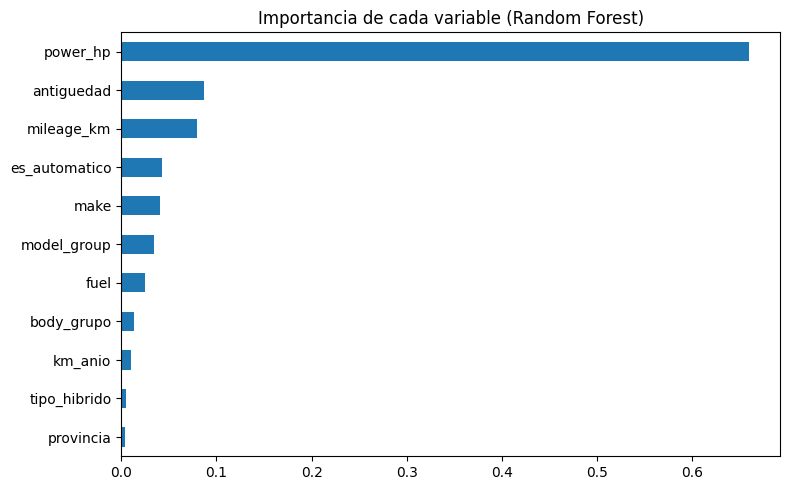

In [28]:
importancias = pd.Series(rf.feature_importances_, index=X_tr.columns).sort_values()

importancias.plot(kind="barh", figsize=(8, 5), title="Importancia de cada variable (Random Forest)")
plt.tight_layout()
plt.show()

In [29]:
pruebas = {
    "completo":         [],
    "sin km_anio":      ["km_anio"],
    "sin body_grupo":   ["body_grupo"],
    "sin provincia":    ["provincia"],
    "sin tipo_hibrido": ["tipo_hibrido"],
    "sin las 4":        ["km_anio", "body_grupo", "provincia", "tipo_hibrido"],
}

filas = []
for nombre, quitar in pruebas.items():
    cols = [c for c in X_tr.columns if c not in quitar]
    modelo = RandomForestRegressor(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=42)
    modelo.fit(X_tr[cols], y_tr)
    filas.append({"prueba": nombre, **metricas(y_val, modelo.predict(X_val[cols]))})

pd.DataFrame(filas).sort_values("MAE_€")

,prueba,MAE_€,MAPE_%,R2
3,sin provincia,2545,9.63,0.893
1,sin km_anio,2549,9.65,0.893
0,completo,2562,9.69,0.891
4,sin tipo_hibrido,2564,9.69,0.891
5,sin las 4,2575,9.77,0.892
2,sin body_grupo,2602,9.85,0.889


# CAT BOOST

In [31]:
cols_final = list(X_tr.columns)   # las 11 variables

In [32]:
def version_texto(indices):
    d = X.loc[indices].copy()          # X original, con texto
    d["power_hp"] = (d["power_hp"].fillna(d["model_group"].map(med_modelo))
                     .fillna(d["make"].map(med_marca)).fillna(med_global))
    d["body_grupo"] = (d["body_grupo"].fillna(d["model_group"].map(moda_body))
                       .fillna("Desconocido"))
    return d[cols_final]

X_tr_cb   = version_texto(X_tr.index)
X_val_cb  = version_texto(X_val.index)
X_test_cb = version_texto(X_test.index)

cat_cols_cb = X_tr_cb.select_dtypes(exclude="number").columns.tolist()
print(cat_cols_cb)
X_tr_cb.head()

['make', 'model_group', 'fuel', 'tipo_hibrido', 'body_grupo', 'provincia']


,make,model_group,fuel,tipo_hibrido,es_automatico,body_grupo,provincia,antiguedad,mileage_km,km_anio,power_hp
45358,Volkswagen,Polo,Gasolina,No híbrido,1,Turismo,Sevilla,8.279261,127666,15419.975694,200.0
46993,Kia,Niro,Eléctrico,No híbrido,1,SUV,Otras,4.109514,91877,22357.144737,204.0
17062,Nissan,Qashqai,Gasolina,No híbrido,0,SUV,Las Palmas,4.358658,36170,8298.424937,140.0
43877,Opel,Insignia,Diésel,No híbrido,1,Turismo,Cádiz,8.446270,132114,15641.698055,170.0
32369,SEAT,Leon,Gasolina,No híbrido,0,Turismo,Málaga,4.358658,37441,8590.028423,131.0


In [36]:
from catboost import CatBoostRegressor

cb = CatBoostRegressor(
    iterations=5000,          # máximo de árboles
    learning_rate=0.08,       # cuánto corrige cada árbol
    depth=6,                  # profundidad de cada árbol
    random_seed=42,
    verbose=200               # muestra el progreso cada 200 árboles
)
cb.fit(
    X_tr_cb, y_tr,
    cat_features=cat_cols_cb,
    eval_set=(X_val_cb, y_val),   # validación, nunca el test
    early_stopping_rounds=100     # para si deja de mejorar
)

0:	learn: 0.4811105	test: 0.4809750	best: 0.4809750 (0)	total: 49.5ms	remaining: 4m 7s
200:	learn: 0.1424301	test: 0.1411145	best: 0.1411145 (200)	total: 7.55s	remaining: 3m
400:	learn: 0.1324648	test: 0.1340221	best: 0.1340112 (397)	total: 14.9s	remaining: 2m 50s
600:	learn: 0.1269579	test: 0.1306679	best: 0.1306679 (600)	total: 22.3s	remaining: 2m 43s
800:	learn: 0.1229240	test: 0.1287594	best: 0.1287594 (800)	total: 29.8s	remaining: 2m 36s
1000:	learn: 0.1200011	test: 0.1273609	best: 0.1273609 (1000)	total: 37.4s	remaining: 2m 29s
1200:	learn: 0.1175702	test: 0.1263825	best: 0.1263825 (1200)	total: 45.1s	remaining: 2m 22s
1400:	learn: 0.1153934	test: 0.1255472	best: 0.1255472 (1400)	total: 52.7s	remaining: 2m 15s
1600:	learn: 0.1135434	test: 0.1250587	best: 0.1250547 (1592)	total: 1m	remaining: 2m 8s
1800:	learn: 0.1118421	test: 0.1244553	best: 0.1244537 (1793)	total: 1m 7s	remaining: 2m
2000:	learn: 0.1102401	test: 0.1239907	best: 0.1239841 (1997)	total: 1m 15s	remaining: 1m 53s
22

CatBoostRegressor(depth=6, iterations=5000, learning_rate=0.08, loss_function='RMSE', random_seed=42, verbose=200)

In [34]:
pd.DataFrame({
    "RF val":       metricas(y_val, rf.predict(X_val[cols_final])),
    "CatBoost tr":  metricas(y_tr,  cb.predict(X_tr_cb)),
    "CatBoost val": metricas(y_val, cb.predict(X_val_cb)),
})

,RF val,CatBoost tr,CatBoost val
MAE_€,2562.000,2128.000,2378.000
MAPE_%,9.690,8.590,9.130
R2,0.891,0.937,0.914


In [37]:
pd.DataFrame({
    "RF val":       metricas(y_val, rf.predict(X_val[cols_final])),
    "CatBoost tr":  metricas(y_tr,  cb.predict(X_tr_cb)),
    "CatBoost val": metricas(y_val, cb.predict(X_val_cb)),
})

,RF val,CatBoost tr,CatBoost val
MAE_€,2562.000,1807.000,2228.000
MAPE_%,9.690,7.450,8.680
R2,0.891,0.958,0.926


In [38]:
# Edad redondeada a años enteros
edad_tr  = X_tr_cb["antiguedad"].round()
edad_val = X_val_cb["antiguedad"].round()

# Medianas aprendidas SOLO en train (en log), de más concreta a más general
tabla_tr = pd.DataFrame({"make": X_tr_cb["make"], "model": X_tr_cb["model_group"],
                         "edad": edad_tr, "y": y_tr})
med_mme = tabla_tr.groupby(["make", "model", "edad"])["y"].median()
med_mm  = tabla_tr.groupby(["make", "model"])["y"].median()
med_m   = tabla_tr.groupby("make")["y"].median()
med_glob = y_tr.median()

# Predecir en validación con fallback en cascada
claves_mme = list(zip(X_val_cb["make"], X_val_cb["model_group"], edad_val))
claves_mm  = list(zip(X_val_cb["make"], X_val_cb["model_group"]))

pred_base = (pd.Series(med_mme.reindex(claves_mme).values, index=X_val_cb.index)
             .fillna(pd.Series(med_mm.reindex(claves_mm).values, index=X_val_cb.index))
             .fillna(X_val_cb["make"].map(med_m))
             .fillna(med_glob))

pd.DataFrame({
    "Baseline val": metricas(y_val, pred_base),
    "RF val":       metricas(y_val, rf.predict(X_val[cols_final])),
    "CatBoost val": metricas(y_val, cb.predict(X_val_cb)),
})

,Baseline val,RF val,CatBoost val
MAE_€,3327.000,2562.000,2228.000
MAPE_%,13.130,9.690,8.680
R2,0.848,0.891,0.926


In [39]:
X_train_cb = version_texto(X_train.index)

cb_final = CatBoostRegressor(
    iterations=5000,
    learning_rate=0.1,
    depth=6,
    random_seed=42,
    verbose=1000
)
cb_final.fit(X_train_cb, y_train, cat_features=cat_cols_cb)

resultado_test = pd.DataFrame({
    "CatBoost train": metricas(y_train, cb_final.predict(X_train_cb)),
    "CatBoost TEST":  metricas(y_test,  cb_final.predict(X_test_cb)),
})
resultado_test

0:	learn: 0.4729103	total: 40.3ms	remaining: 3m 21s
1000:	learn: 0.1173245	total: 40.4s	remaining: 2m 41s
2000:	learn: 0.1076430	total: 1m 22s	remaining: 2m 3s
3000:	learn: 0.1015064	total: 2m 4s	remaining: 1m 22s
4000:	learn: 0.0966070	total: 2m 45s	remaining: 41.4s
4999:	learn: 0.0924156	total: 3m 27s	remaining: 0us


,CatBoost train,CatBoost TEST
MAE_€,1770.00,2118.000
MAPE_%,7.30,8.480
R2,0.96,0.924


In [40]:
import os
os.makedirs("modelos", exist_ok=True)
cb_final.save_model("modelos/catboost_final.cbm")

In [41]:
# Residuo en log = log(real) - log(predicho)  → en %: exp(residuo) - 1
residuos = y_test - cb_final.predict(X_test_cb)

p10 = residuos.quantile(0.10)
p90 = residuos.quantile(0.90)

print(f"Límite chollo: {np.exp(p10) - 1:+.1%} respecto al precio justo")
print(f"Límite caro:   {np.exp(p90) - 1:+.1%} respecto al precio justo")

Límite chollo: -12.2% respecto al precio justo
Límite caro:   +13.9% respecto al precio justo


In [42]:
import json

df_txt = X.loc[X_train.index]   # texto original de train

config = {
    "p10": float(p10),
    "p90": float(p90),
    "columnas": cols_final,
    "modelos_por_marca": df_txt.groupby("make")["model_group"]
                               .apply(lambda s: sorted(s.unique())).to_dict(),
    "fuel":          sorted(df_txt["fuel"].unique()),
    "tipo_hibrido":  sorted(df_txt["tipo_hibrido"].unique()),
    "body_grupo":    sorted(df_txt["body_grupo"].dropna().unique()),
    "provincia":     sorted(df_txt["provincia"].unique()),
    "mae_test":      2118,
}

with open("modelos/config_app.json", "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)